## Visualize ACT-based reference samples

_Change for each model_

In [2]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

import json
import torch

from torchvision.models import ResNet50_Weights

from  configs.general_cofig import *
from interpretability.visualizations.visualization_functions import report_polysem, plot_polysem, visualize_neuron
from interpretability.adapters.semanticlens.ResNet50 import ResNetAdapter
#from interpretability.adapters.semanticlens.VGG16 import VGG16Adapter
from interpretability.adapters.semanticlens.ViT import ViTAdapter
#from interpretability.adapters.semanticlens.ViLT import ViLTAdapter
from interpretability.adapters.semanticlens.Qwen import QwenAdapter
from models.create_model import create_resnet50
from my_datasets.imagenet_mini import ImagenetMini

from semanticlens.component_visualization.activation_based import CustomActivationComponentVisualizer
from semanticlens.component_visualization.aggregators import aggregate_conv_mean


weights = ResNet50_Weights.IMAGENET1K_V2
transform = weights.transforms()

model = create_resnet50()
model_name = "resnet_50"

adapter = ResNetAdapter()

layer = ["layer4.1.conv2"]
neuron_id = 386

aggr_func = aggregate_conv_mean

NUM_SAMPLES = 10


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using device: cpu


_Independent on model_

Embedding model: CLIP_Mobile


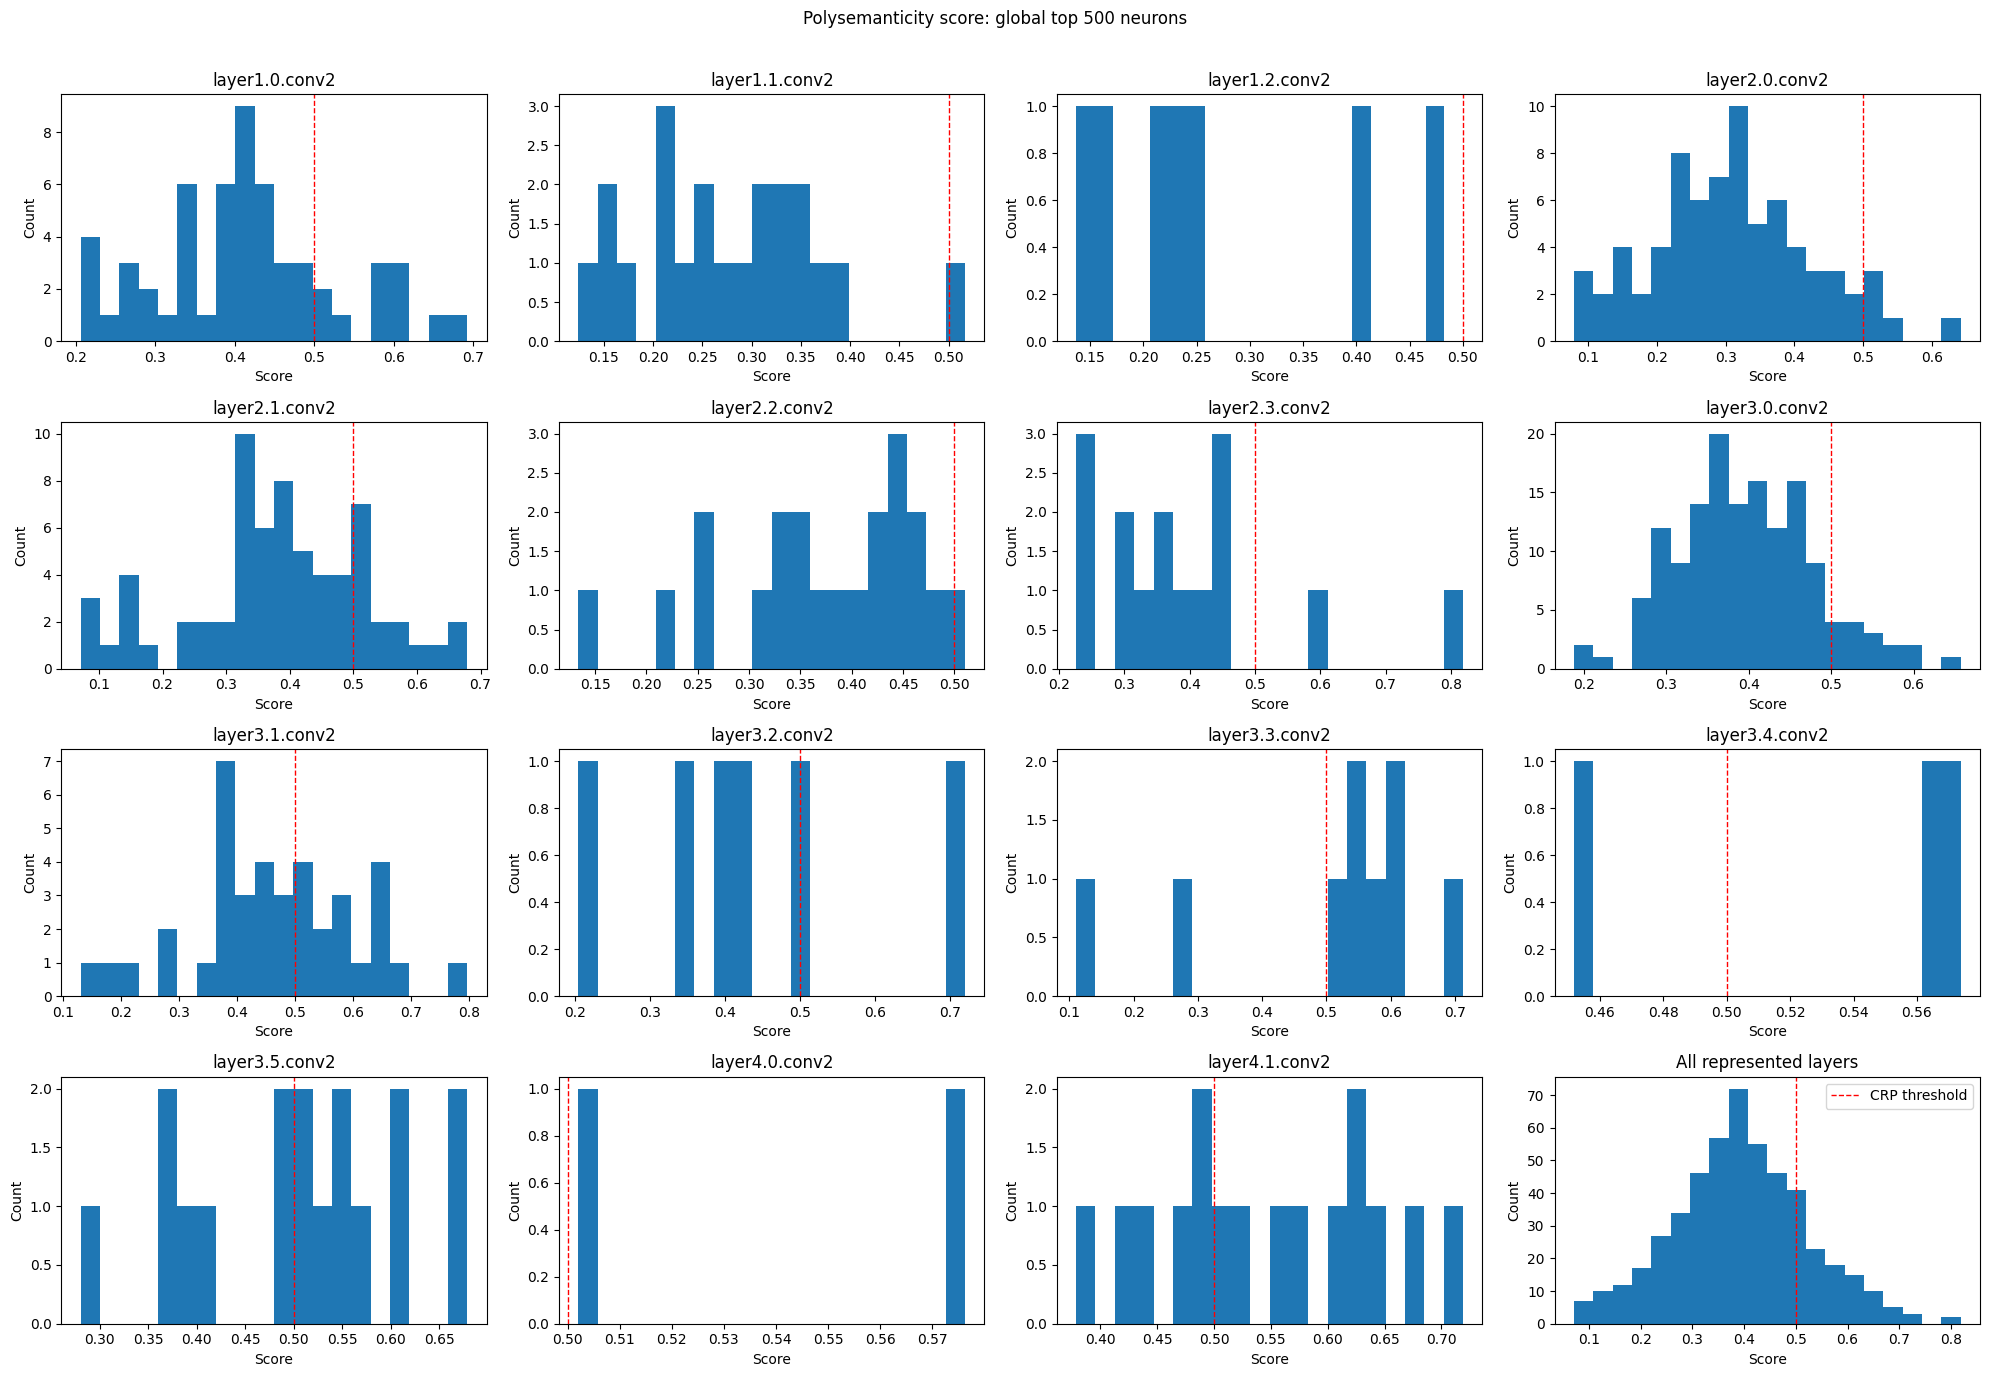

All scores: 500

Polysemanticity score: global top 500 neurons
neurons: 500
general polysemanticity level: 0.393373
median polysemanticity: 0.390160

layer1.0.conv2: n=56, mean=0.414845
  most polysemantic:
    33: 0.692801
    9: 0.650793
    63: 0.609689
    8: 0.604726
    7: 0.600112
  least polysemantic:
    57: 0.205804
    24: 0.207810
    30: 0.213761
    35: 0.223612
    5: 0.239966

layer1.1.conv2: n=21, mean=0.276548
  most polysemantic:
    46: 0.516635
    24: 0.392509
    30: 0.373515
    12: 0.355136
    20: 0.347391
  least polysemantic:
    9: 0.124194
    5: 0.159972
    18: 0.160633
    49: 0.168329
    15: 0.209481

layer1.2.conv2: n=7, mean=0.267610
  most polysemantic:
    25: 0.482353
    38: 0.411786
    43: 0.245839
    5: 0.226825
    12: 0.213041
  least polysemantic:
    11: 0.137045
    58: 0.156378
    12: 0.213041
    5: 0.226825
    43: 0.245839

layer2.0.conv2: n=74, mean=0.309070
  most polysemantic:
    115: 0.641903
    108: 0.546869
    118: 0.52738

In [5]:
# ---------------------------- Polysemanticity distribution -----------------------------
EMBEDDING_MODEL = "CLIP_Mobile"


polysem_score_path = f"{OUTPUTS}/polysemanticity_scores/{EMBEDDING_MODEL}_{N_SAMPLES}_ref_samples/polysemanticity_score_{model_name}.json"
polysem_score = json.load(open(polysem_score_path, "r"))

polysem_score_parsed = {
    l: {
        int(n_id): float(score[0])
        for n_id, score in info.items()
    }
    for l, info in polysem_score.items()
}
print(f"Embedding model: {EMBEDDING_MODEL}")
plot_polysem(polysem_scores=polysem_score_parsed)

report_polysem(
    polysem_scores=polysem_score_parsed,
    k_polysem_n=5,
)

directory C:\Users\lvche\PycharmProjects\MasterThesis\outputs\semanticlens_cache\CustomActivationComponentVisualizer\imagenetmini-1000\resnet_50
fpath C:\Users\lvche\PycharmProjects\MasterThesis\outputs\semanticlens_cache\CustomActivationComponentVisualizer\imagenetmini-1000\resnet_50\aggregate_conv_mean-10-layer4.1.conv2.safetensors
directory C:\Users\lvche\PycharmProjects\MasterThesis\outputs\semanticlens_cache\CustomActivationComponentVisualizer\imagenetmini-1000\resnet_50
fpath C:\Users\lvche\PycharmProjects\MasterThesis\outputs\semanticlens_cache\CustomActivationComponentVisualizer\imagenetmini-1000\resnet_50\aggregate_conv_mean-10-layer4.1.conv2.safetensors
finding top k neurons
Loading top k neurons stats. from existing files 
Crop_db was loaded from an existing file. It contains 5000 crops.
creating crop_db for layer layer4.1.conv2
--- layer4.1.conv2, 386 neuron ---
Mean activation: 6.21875
Polysemanticity score: 0.6752


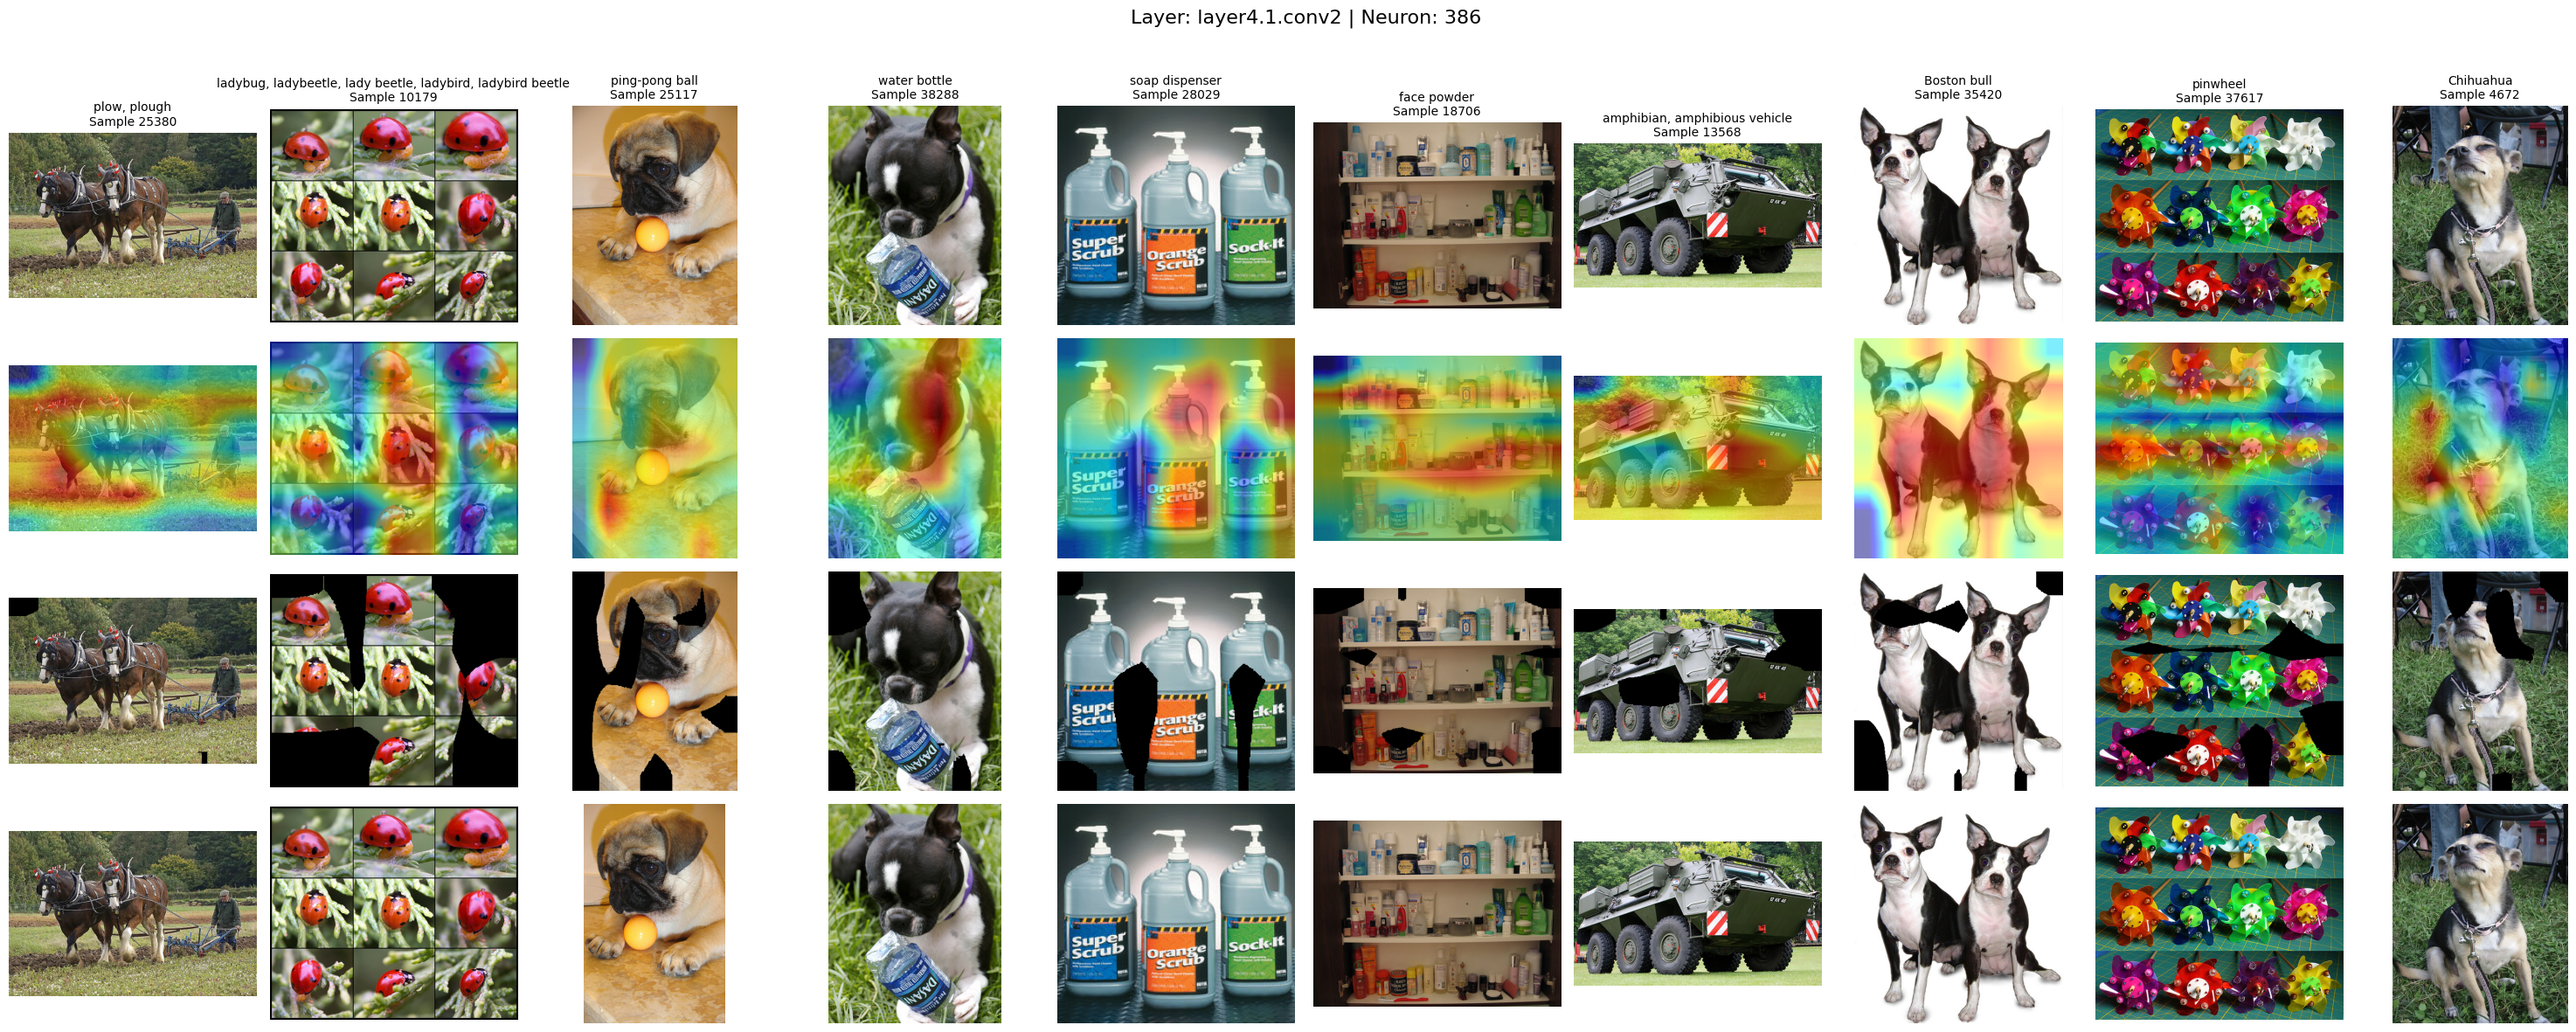

In [64]:
# ------------------------------ Visualize chosen neuron ---------------------------------
import timm
from torchvision.transforms import v2 as transforms

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model.eval().to(device)
model.name = model_name

data_config = timm.data.resolve_data_config({}, model=model)
model_transform = timm.data.create_transform(**data_config)

# same for all models
fm_transform = transforms.Compose(
        [
            transforms.Resize(data_config["input_size"][1], interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(data_config["input_size"][1]),
        ]
)
# a) Dataset for the model being analyzed
dataset_model = ImagenetMini(
    wordnet_ids_to_classes_path=f"{ROOT}/datasets/input_files/wordnet_ids_to_classes.txt",
    transform=model_transform,
)
dataset_model.name = "imagenetmini-1000"

# b) Dataset for the foundation model
# We don't apply normalization, as the foundation model has its own preprocessing.
dataset_fm = ImagenetMini(
    wordnet_ids_to_classes_path=f"{ROOT}/datasets/input_files/wordnet_ids_to_classes.txt",
    transform=fm_transform,
)

cv_obj = CustomActivationComponentVisualizer(
    model=model,
    dataset_model=dataset_model,
    dataset_fm=dataset_fm,
    layer_names=layer,
    num_samples=NUM_SAMPLES,
    device=device,
    adapter=adapter,
    aggregate_fn=aggr_func,
    cache_dir=f"{OUTPUTS}/semanticlens_cache",
    model_name=model_name,
)

cv_obj.run()
cv_obj.create_crop_db()

visualize_neuron(
    cv_object=cv_obj,
    dataset=dataset_model,
    polysem_scores_model=polysem_score,
    layer=layer[0],
    neuron_id=neuron_id,
    print_info=True
)


--- Cluster statistics (cosine distance) ---
 Cluster  N images  Intra distance  Inter distance  Separation
       0         2          0.7202          0.8473      0.1271
       1         2          0.6258          0.9078      0.2820
       2         2          0.6809          0.8920      0.2111
       3         4          0.5210          0.8667      0.3458

Global intra-class distance: 0.5725
Global inter-class distance: 0.8772
Silhouette score:            0.2661
Polysemanticity score:       0.8161


C:\Users\lvche\PycharmProjects\MasterThesis\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


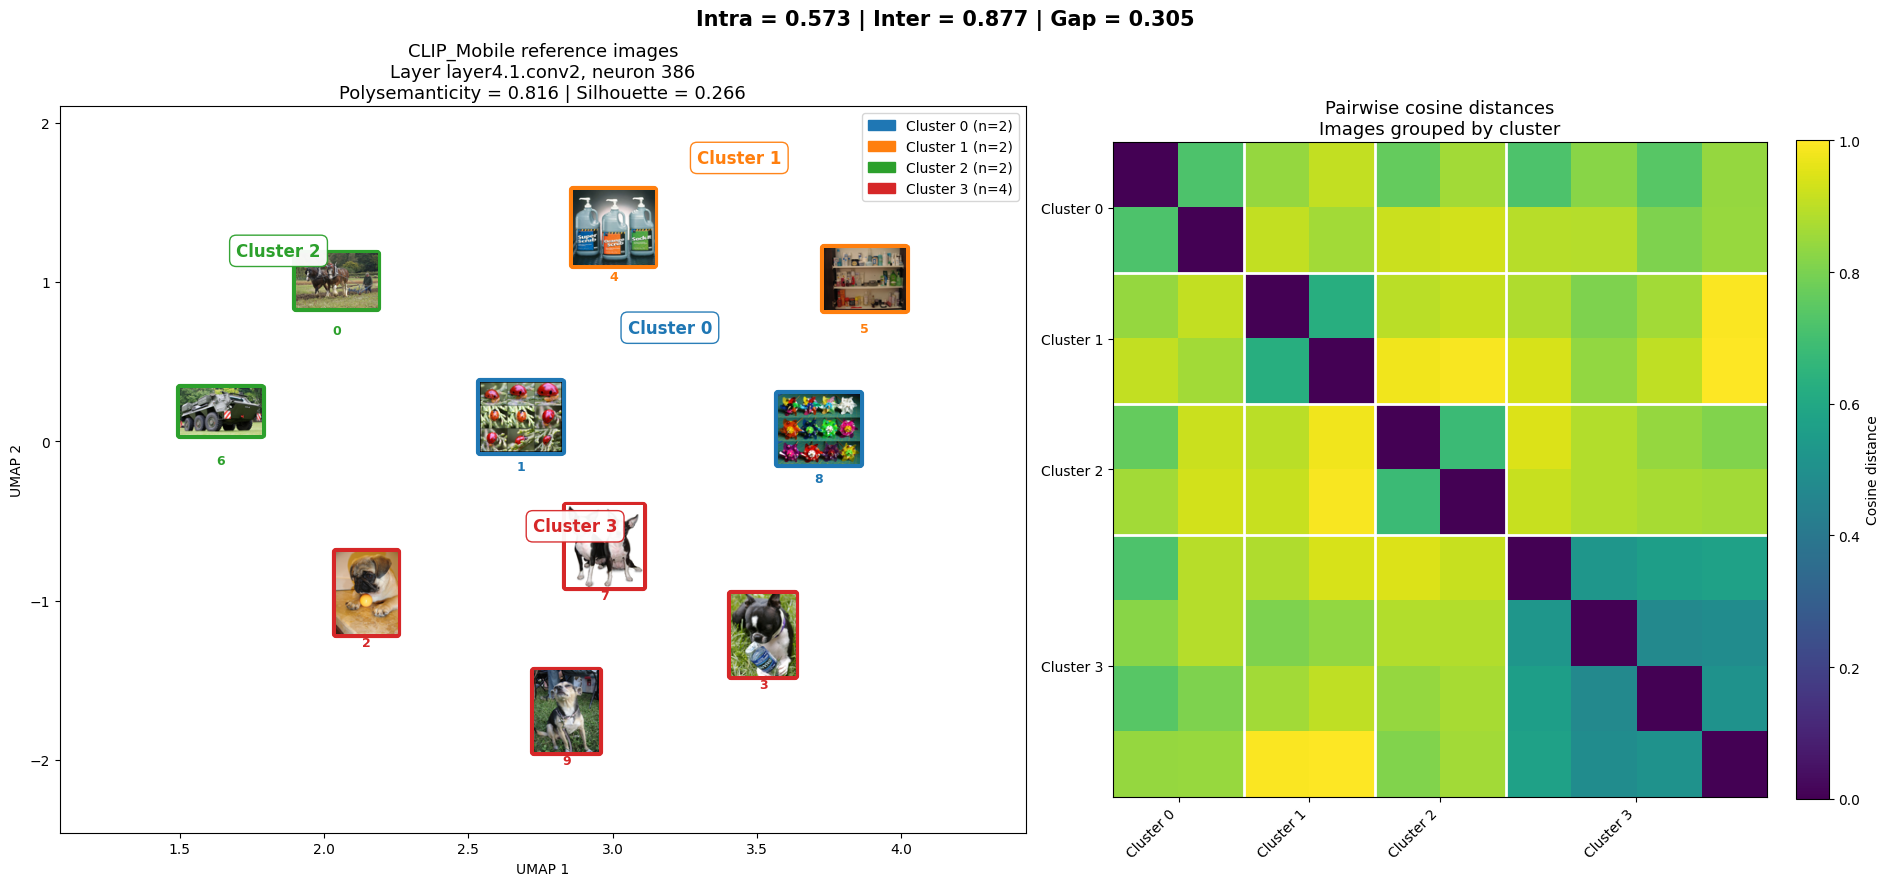


--- Pairwise inter-cluster distances ---
           Cluster 0  Cluster 1  Cluster 2  Cluster 3
Cluster 0        NaN     0.8803     0.8689     0.8199
Cluster 1     0.8803        NaN     0.9447     0.9031
Cluster 2     0.8689     0.9447        NaN     0.8772
Cluster 3     0.8199     0.9031     0.8772        NaN


In [67]:

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import umap
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Patch
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.preprocessing import normalize

from interpretability.attribution_methods.semanticlens.lens import (
    polysemanticity_score,
)

# ---------------- Configuration ----------------

NUM_CLUSTERS = 4
RANDOM_STATE = 42
IMAGE_SIZE = 90
IMAGE_ZOOM = 0.65

COLORS = plt.get_cmap("tab10").colors


def load_reference_image(item):
    if isinstance(item, Image.Image):
        return item.convert("RGB")
    with Image.open(item) as im:
        return im.convert("RGB")


def mean_upper_triangle(matrix):
    """Mean pairwise distance, excluding the diagonal."""
    if len(matrix) < 2:
        return np.nan
    return matrix[np.triu_indices(len(matrix), k=1)].mean()


# ---------------- Load embeddings ----------------

concept_db_acts = torch.load(
    f"{OUTPUTS}/embeddings/semanticlens/"
    f"{N_SAMPLES}_refs_per_neuron/concept_db/"
    f"concept_db_{model_name}.pt",
    map_location="cpu",
    weights_only=False,
)

refs_acts = torch.load(
    f"{OUTPUTS}/top_k_act_neurons/"
    f"top_{K_ACT_NEURONS}_max_samples_{model_name}.pt",
    map_location="cpu",
    weights_only=False,
)

layer_str = layer[0]
reference_image_ids = refs_acts[layer_str][neuron_id]
vectors = concept_db_acts[layer_str][neuron_id]

# Original embedding space: [n_images, embedding_dim]
X = vectors.detach().float().cpu().numpy()
X = normalize(X, norm="l2", axis=1)

n_images = len(X)

if n_images < max(4, NUM_CLUSTERS + 1):
    raise ValueError(
        "Need at least max(4, NUM_CLUSTERS + 1) images."
    )

if len(reference_image_ids) != n_images:
    raise ValueError("Image IDs and embeddings do not match.")

# ---------------- Polysemanticity ----------------

V = vectors.detach().float().cpu().unsqueeze(0)

poly_score = polysemanticity_score(
    V,
    replace_empty_clusters=True,
    n_clusters=NUM_CLUSTERS,
)

if isinstance(poly_score, torch.Tensor):
    poly_score = poly_score.detach().cpu().item()

# ---------------- Original-space cosine distances ----------------

# All distances are calculated from the original
# normalized 512-dimensional embeddings.
D = pairwise_distances(X, metric="cosine")

D = np.clip(D, 0, 2)
np.fill_diagonal(D, 0)

# ---------------- Agglomerative clustering ----------------

# Average linkage:
# distance between clusters = mean cosine distance
# between all cross-cluster embedding pairs.
clustering = AgglomerativeClustering(
    n_clusters=NUM_CLUSTERS,
    metric="precomputed",
    linkage="average",
)

labels = clustering.fit_predict(D)

# Deterministic cluster numbering by first occurrence
unique_labels = np.unique(labels)
label_map = {
    old: new for new, old in enumerate(unique_labels)
}
labels = np.array([label_map[x] for x in labels])

# ---------------- Cluster statistics ----------------

silhouette = silhouette_score(
    D,
    labels,
    metric="precomputed",
)

cluster_stats = []

for c in range(NUM_CLUSTERS):
    idx = np.flatnonzero(labels == c)
    other_idx = np.flatnonzero(labels != c)

    intra = mean_upper_triangle(D[np.ix_(idx, idx)])
    inter = D[np.ix_(idx, other_idx)].mean()

    cluster_stats.append({
        "Cluster": c,
        "N images": len(idx),
        "Intra distance": intra,
        "Inter distance": inter,
        "Separation": inter - intra,
    })

stats_df = pd.DataFrame(cluster_stats)

# Pairwise inter-cluster distances
inter_matrix = np.full(
    (NUM_CLUSTERS, NUM_CLUSTERS),
    np.nan,
)

for a in range(NUM_CLUSTERS):
    for b in range(a + 1, NUM_CLUSTERS):
        ia = np.flatnonzero(labels == a)
        ib = np.flatnonzero(labels == b)

        distance = D[np.ix_(ia, ib)].mean()

        inter_matrix[a, b] = distance
        inter_matrix[b, a] = distance

# Global distances: each unordered image pair counted once
within_pairs = []
between_pairs = []

for i in range(n_images):
    for j in range(i + 1, n_images):
        if labels[i] == labels[j]:
            within_pairs.append(D[i, j])
        else:
            between_pairs.append(D[i, j])

global_intra = (
    np.mean(within_pairs) if within_pairs else np.nan
)
global_inter = (
    np.mean(between_pairs) if between_pairs else np.nan
)

print("\n--- Cluster statistics (cosine distance) ---")
print(stats_df.round(4).to_string(index=False))

print(f"\nGlobal intra-class distance: {global_intra:.4f}")
print(f"Global inter-class distance: {global_inter:.4f}")
print(f"Silhouette score:            {silhouette:.4f}")
print(f"Polysemanticity score:       {poly_score:.4f}")

# ---------------- UMAP visualization only ----------------

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=min(15, n_images - 1),
    min_dist=0.25,
    metric="cosine",
    random_state=RANDOM_STATE,
)

coordinates = reducer.fit_transform(X)

# ---------------- Load image thumbnails ----------------

images = []

for im_id in reference_image_ids:
    if isinstance(im_id, torch.Tensor):
        im_id = im_id.item()

    path = dataset_model.dataset.samples[int(im_id)][0]
    image = load_reference_image(path)

    image = ImageOps.contain(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
    )
    images.append(np.asarray(image))

# ---------------- Visualization ----------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 9),
    gridspec_kw={"width_ratios": [1.35, 1]},
)

ax, ax_heat = axes

# Colored background points
for c in range(NUM_CLUSTERS):
    idx = labels == c

    ax.scatter(
        coordinates[idx, 0],
        coordinates[idx, 1],
        s=130,
        color=COLORS[c],
        alpha=0.25,
        edgecolors=COLORS[c],
        linewidths=1.5,
        zorder=1,
    )

# Image thumbnails with colored cluster borders
for i, (x, y) in enumerate(coordinates):
    c = labels[i]

    image_box = OffsetImage(
        images[i],
        zoom=IMAGE_ZOOM,
    )

    annotation = AnnotationBbox(
        image_box,
        (x, y),
        frameon=True,
        pad=0.15,
        bboxprops={
            "edgecolor": COLORS[c],
            "linewidth": 3,
            "boxstyle": "round,pad=0.15",
        },
        zorder=3,
    )

    ax.add_artist(annotation)

    ax.annotate(
        str(i),
        (x, y),
        xytext=(0, -38),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=COLORS[c],
        zorder=4,
    )

# Cluster labels at projected mean positions
for c in range(NUM_CLUSTERS):
    center = coordinates[labels == c].mean(axis=0)

    ax.annotate(
        f"Cluster {c}",
        center,
        xytext=(0, 65),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
        color=COLORS[c],
        bbox={
            "facecolor": "white",
            "edgecolor": COLORS[c],
            "alpha": 0.95,
            "boxstyle": "round,pad=0.4",
        },
        zorder=5,
    )

ax.set_title(
    f"{EMBEDDING_MODEL} reference images\n"
    f"Layer {layer_str}, neuron {neuron_id}\n"
    f"Polysemanticity = {poly_score:.3f} | "
    f"Silhouette = {silhouette:.3f}",
    fontsize=13,
)

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")

ax.legend(
    handles=[
        Patch(
            color=COLORS[c],
            label=f"Cluster {c} (n={(labels == c).sum()})"
        )
        for c in range(NUM_CLUSTERS)
    ],
    loc="best",
)

ax.margins(0.25)

# ---------------- Distance heatmap ----------------

order = np.argsort(labels, kind="stable")
D_sorted = D[np.ix_(order, order)]
sorted_labels = labels[order]

im = ax_heat.imshow(
    D_sorted,
    cmap="viridis",
    vmin=0,
    vmax=max(1e-8, float(D_sorted.max())),
    interpolation="nearest",
)

# Cluster boundaries
boundaries = np.cumsum(
    np.bincount(sorted_labels, minlength=NUM_CLUSTERS)
)

for boundary in boundaries[:-1]:
    ax_heat.axhline(
        boundary - 0.5,
        color="white",
        linewidth=2,
    )
    ax_heat.axvline(
        boundary - 0.5,
        color="white",
        linewidth=2,
    )

starts = np.r_[0, boundaries[:-1]]
centers = (starts + boundaries - 1) / 2

ax_heat.set_xticks(centers)
ax_heat.set_yticks(centers)

ax_heat.set_xticklabels(
    [f"Cluster {c}" for c in range(NUM_CLUSTERS)],
    rotation=45,
    ha="right",
)
ax_heat.set_yticklabels(
    [f"Cluster {c}" for c in range(NUM_CLUSTERS)]
)

ax_heat.set_title(
    "Pairwise cosine distances\n"
    "Images grouped by cluster",
    fontsize=13,
)

fig.colorbar(
    im,
    ax=ax_heat,
    fraction=0.046,
    pad=0.04,
    label="Cosine distance",
)

fig.suptitle(
    f"Intra = {global_intra:.3f} | "
    f"Inter = {global_inter:.3f} | "
    f"Gap = {global_inter - global_intra:.3f}",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

# ---------------- Inter-cluster matrix ----------------

inter_df = pd.DataFrame(
    inter_matrix,
    index=[
        f"Cluster {c}" for c in range(NUM_CLUSTERS)
    ],
    columns=[
        f"Cluster {c}" for c in range(NUM_CLUSTERS)
    ],
)

print("\n--- Pairwise inter-cluster distances ---")
print(inter_df.round(4).to_string())
